<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/04_nlp/02_text_classification_app_swahili_news.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📰 Application · Text classification: sorting Swahili news with a transformer

**Swahili** (*Kiswahili*) is spoken by 100+ million people across East and Central Africa. Newsrooms in Tanzania and
Kenya publish thousands of articles every week, and sorting them by topic is a classic NLP job. In 2020 the
*Swahili: News Classification Dataset* (David Davis, Zenodo) collected ~30 000 Tanzanian news articles in six
categories, and it became a **Zindi** challenge (AI4D Africa). It is a perfect playground to compare the two eras of NLP:

- 🧮 **The classical era**: TF-IDF + linear model (fast, strong, explainable). You built one in the AfriSenti quest.
- 🤖 **The transformer era** (since 2018, *BERT*): a neural network **pre-trained** on huge amounts of text learns
  the language first, then is **fine-tuned** on our task with a few thousand labelled examples.

We will use **AfroXLMR-mini** (Masakhane / Davlan Adelani): a small multilingual model whose pre-training was
adapted to 17 African languages, including Swahili. It's small enough for a laptop.

| Step | Why it matters |
|---|---|
| 1. Data & EDA | know the classes and the text lengths (transformers have a max length!) |
| 2. Validation split | stratified, decided before any model |
| 3. TF-IDF baseline | the score to beat, in seconds |
| 4. Tokenizer | how a transformer cuts words into sub-words |
| 5. Fine-tuning | transfer learning: reuse knowledge, adapt to the task |
| 6. Compare, analyse, submit | honest comparison on the same validation set |

⏱️ Runtime: ~10 minutes on a laptop GPU (Apple M-series / NVIDIA), longer on CPU (reduce `N_TRAIN_TRANSFORMER`).

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentencepiece"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay

quest("Sorting Swahili news", chapter="Track 4 · NLP · Text classification", xp=250)
DEVICE = get_device()

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Sorting Swahili news
   Track 4 · NLP · Text classification
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


⚙️  Using device: mps  (Apple Silicon GPU (Metal))


## 1. The data 📥

The dataset (CC-BY 4.0) is on the Hugging Face Hub with a labelled train set (22 207 articles) and a labelled test
set (7 338 articles). We keep the test set hidden until the end: it plays the role of the **private leaderboard**.

In [3]:
LABELS = ["uchumi", "kitaifa", "michezo", "kimataifa", "burudani", "afya"]
LABELS_EN = {"uchumi": "economy", "kitaifa": "national", "michezo": "sports",
             "kimataifa": "international", "burudani": "entertainment", "afya": "health"}

df = hf_parquet("community-datasets/swahili_news", "train", config="swahili_news")
test = hf_parquet("community-datasets/swahili_news", "test", config="swahili_news")
df["category"] = df["label"].map(dict(enumerate(LABELS)))
test["category"] = test["label"].map(dict(enumerate(LABELS)))
print(df.shape, test.shape)
print(df.loc[0, "text"][:400], "…")

(22207, 3) (7338, 3)
 Bodi ya Utalii Tanzania (TTB) imesema, itafanya misafara ya kutangaza utalii kwenye miji minne nchini China kati ya Juni 19 hadi Juni 26 mwaka huu.Misafara hiyo itatembelea miji ya Beijing Juni 19, Shanghai Juni 21, Nanjig Juni 24 na Changsha Juni 26.Mwenyekiti wa bodi TTB, Jaji Mstaafu Thomas Mihayo ameyasema hayo kwenye mkutano na waandishi wa habari jijini Dar es Salaam.“Tunafanya jitihada kuh …


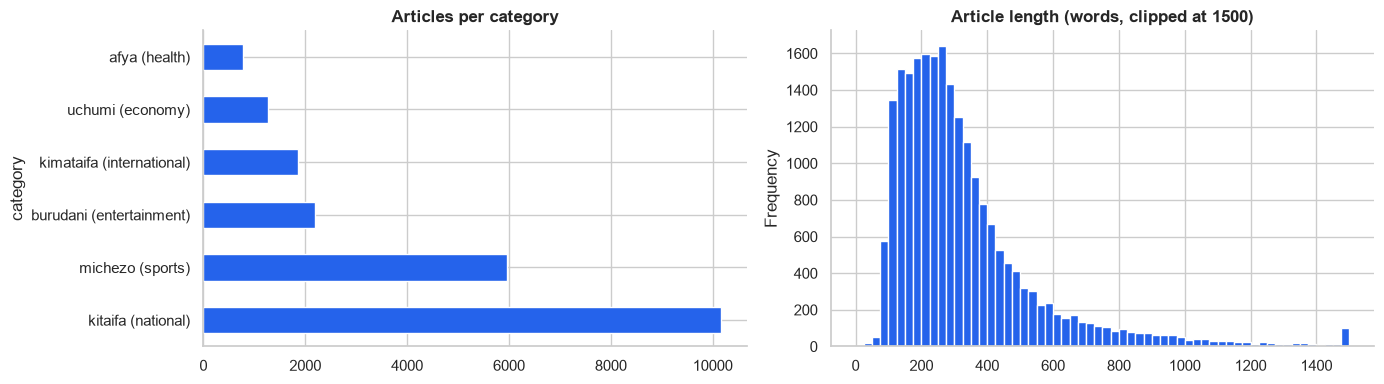

Median length: 270 words


In [4]:
df["n_words"] = df["text"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["category"].map(lambda c: f"{c} ({LABELS_EN[c]})").value_counts().plot.barh(ax=axes[0], title="Articles per category")
df["n_words"].clip(upper=1500).plot.hist(bins=60, ax=axes[1], title="Article length (words, clipped at 1500)")
plt.tight_layout(); plt.show()
print(f"Median length: {df['n_words'].median():.0f} words")

**Observations.** The classes are imbalanced: *kitaifa* (national news) dominates, *afya* (health) and *burudani*
(entertainment) are rare. Articles are long (hundreds of words) while small transformers read at most 512 *tokens*,
and we will use only 128 to stay fast: the **headline and first lines** of a news article usually tell its topic.

## 2. Validation split 🛡️

One stratified split (85% / 15%), fixed seed, used by **every** model so comparisons are fair.

In [5]:
train, valid = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=SEED)
print(len(train), len(valid))
lb = Leaderboard("swahili_news", metric="macro_F1")

18875 3332


## 3. The classical baseline: TF-IDF + logistic regression 🧮

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=300_000, sublinear_tf=True),
                      LogisticRegression(max_iter=2000, C=10, class_weight="balanced"))
tfidf.fit(train["text"], train["label"])
lb.add("TF-IDF + LogReg (all 18.9k articles)", f1_score(valid["label"], tfidf.predict(valid["text"]), average="macro"),
       accuracy=accuracy_score(valid["label"], tfidf.predict(valid["text"])))

📋 TF-IDF + LogReg (all 18.9k articles): macro_F1 = 0.81917


For a fair fight with the transformer (which we will train on a subset to save time), let's also train the baseline
on the **same 8 000 articles** and on the **first 128 words** only.

In [7]:
N_TRAIN_TRANSFORMER = 8_000          # ⏱️ lower it on CPU (e.g. 2 000), raise it on a big GPU (all 18 876)
sub = train.sample(N_TRAIN_TRANSFORMER, random_state=SEED)
first_words = lambda s: s.str.split().str[:128].str.join(" ")
tfidf_small = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                            LogisticRegression(max_iter=2000, C=10, class_weight="balanced"))
tfidf_small.fit(first_words(sub["text"]), sub["label"])
pred = tfidf_small.predict(first_words(valid["text"]))
lb.add("TF-IDF + LogReg (8k articles, 128 words)", f1_score(valid["label"], pred, average="macro"),
       accuracy=accuracy_score(valid["label"], pred))
lb.show()

📋 TF-IDF + LogReg (8k articles, 128 words): macro_F1 = 0.80115


,,model,macro_F1,accuracy
rank,,,,
1,🥇,TF-IDF + LogReg (all 18.9k articles),0.81917,0.893157
2,🥈,"TF-IDF + LogReg (8k articles, 128 words)",0.80115,0.883253


In [8]:
checkpoint("swahili_news/baseline", xp=40)

✅ Checkpoint · swahili_news/baseline (+40 XP)
   █████████░░░░░░░░░░░░░░░ 40/100 XP


## 4. Meet the tokenizer ✂️

Transformers don't use a fixed word list: they use **sub-words** (here *SentencePiece*). Frequent words stay whole,
rare words are cut into frequent pieces. No word is ever "unknown", and the model can share knowledge between
*tangaza* (announce), *ametangaza* (he announced) and *imetangazwa* (it was announced). Very handy for an
agglutinative language like Swahili!

In [9]:
import logging
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding
transformers.logging.set_verbosity_error()          # keep the notebook readable (hide loading reports)
transformers.utils.logging.disable_progress_bar()
from datasets.utils.logging import disable_progress_bar
disable_progress_bar()

MODEL_NAME = "Davlan/afro-xlmr-mini"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
for sentence in ["Serikali imetangaza bajeti mpya ya afya", "Simba SC imeshinda mabao matatu kwa sifuri"]:
    print(sentence, "\n   →", tokenizer.tokenize(sentence))

Serikali imetangaza bajeti mpya ya afya 
   → ['▁Serikali', '▁ime', 'tangaza', '▁bajeti', '▁mpya', '▁ya', '▁afya']
Simba SC imeshinda mabao matatu kwa sifuri 
   → ['▁Simba', '▁SC', '▁ime', 'shinda', '▁mabao', '▁mata', 'tu', '▁kwa', '▁si', 'furi']


In [10]:
MAX_LEN = 128
lengths = [len(ids) for ids in tokenizer(valid["text"].head(500).tolist())["input_ids"]]
print(f"Median article length: {np.median(lengths):.0f} tokens → we keep the first {MAX_LEN}.")

Median article length: 415 tokens → we keep the first 128.


## 5. Fine-tuning: transfer learning in action 🔥

The recipe, used in thousands of competitions:

1. Load the **pre-trained** body of the model + a **new classification head** (6 outputs, randomly initialised).
2. Feed our labelled articles, compare the predictions with the truth (cross-entropy loss), and nudge **all** the
   weights a little (small learning rate: we don't want to erase what the model knows about Swahili).
3. Evaluate on the validation set after each epoch.

The Hugging Face `Trainer` handles batching, the GPU (CUDA or Apple MPS), the optimiser and the logs.

In [11]:
from datasets import Dataset

def to_dataset(frame):
    ds = Dataset.from_pandas(frame[["text", "label"]].reset_index(drop=True))
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN), batched=True, remove_columns=["text"])

train_ds, valid_ds, test_ds = to_dataset(sub), to_dataset(valid), to_dataset(test)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS),
    id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)})
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"macro_f1": f1_score(labels, preds, average="macro"), "accuracy": accuracy_score(labels, preds)}

args = TrainingArguments(
    output_dir=str(RUNS_DIR / "swahili_news_afroxlmr"),
    num_train_epochs=2,
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    warmup_steps=50,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=100,
    report_to="none",
    dataloader_num_workers=NUM_WORKERS,
    dataloader_pin_memory=(DEVICE == "cuda"),
    seed=SEED,
)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=valid_ds,
                  processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
                  compute_metrics=compute_metrics)
trainer.train();

118M parameters


{'loss': '1.562', 'grad_norm': '3.162', 'learning_rate': '4.742e-05', 'epoch': '0.2'}


{'loss': '1.045', 'grad_norm': '2.801', 'learning_rate': '4.216e-05', 'epoch': '0.4'}


{'loss': '0.8053', 'grad_norm': '6.619', 'learning_rate': '3.689e-05', 'epoch': '0.6'}


{'loss': '0.7155', 'grad_norm': '5.337', 'learning_rate': '3.163e-05', 'epoch': '0.8'}


{'loss': '0.6234', 'grad_norm': '5.789', 'learning_rate': '2.637e-05', 'epoch': '1'}


... (3 outputs left out)

{'loss': '0.5086', 'grad_norm': '14.36', 'learning_rate': '1.058e-05', 'epoch': '1.6'}


{'loss': '0.4559', 'grad_norm': '7.547', 'learning_rate': '5.316e-06', 'epoch': '1.8'}


{'loss': '0.4645', 'grad_norm': '1.984', 'learning_rate': '5.263e-08', 'epoch': '2'}


{'eval_loss': '0.4533', 'eval_macro_f1': '0.7246', 'eval_accuracy': '0.8944', 'eval_runtime': '14.81', 'eval_samples_per_second': '225', 'eval_steps_per_second': '3.579', 'epoch': '2'}
{'train_runtime': '341.6', 'train_samples_per_second': '46.84', 'train_steps_per_second': '2.928', 'train_loss': '0.7236', 'epoch': '2'}


In [12]:
metrics = trainer.evaluate()
lb.add(f"AfroXLMR-mini fine-tuned (8k articles, {MAX_LEN} tokens)", metrics["eval_macro_f1"], accuracy=metrics["eval_accuracy"])
lb.show()

{'eval_loss': '0.4533', 'eval_macro_f1': '0.7246', 'eval_accuracy': '0.8944', 'eval_runtime': '13.48', 'eval_samples_per_second': '247.2', 'eval_steps_per_second': '3.932', 'epoch': '2'}
📋 AfroXLMR-mini fine-tuned (8k articles, 128 tokens): macro_F1 = 0.72462


,,model,macro_F1,accuracy
rank,,,,
1,🥇,TF-IDF + LogReg (all 18.9k articles),0.81917,0.893157
2,🥈,"TF-IDF + LogReg (8k articles, 128 words)",0.80115,0.883253
3,🥉,"AfroXLMR-mini fine-tuned (8k articles, 128 tok...",0.72462,0.894358


In [13]:
checkpoint("swahili_news/transformer", xp=80, msg="You fine-tuned a transformer!")

✅ Checkpoint · swahili_news/transformer (+80 XP) You fine-tuned a transformer!
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ██░░░░░░░░░░░░░░░░░░░░░░ 120/300 XP


**Reading the leaderboard: look at both columns!** The fine-tuned transformer reaches an **accuracy** as high as the
best TF-IDF model (≈ 0.89), yet by far the **lowest macro-F1**. How is that possible? Accuracy is dominated by the big classes (*kitaifa*,
*michezo*), where the transformer excels. Macro-F1 gives the same weight to the rare classes (*afya*, *uchumi*),
and there the transformer, trained only 2 epochs on 8 000 articles without class weights, is weaker than the
TF-IDF models (which use `class_weight="balanced"`).

Lesson: **the metric decides the winner**, so always optimise for the competition's metric. And the full TF-IDF
model, which sees all the articles and every word of them, is a very tough baseline on long, topical texts.
The two families make **different** mistakes, which is exactly when an **ensemble** shines. Let's try.

## 6. Ensemble, analyse, submit 🤝

We average the class probabilities of the transformer and the full TF-IDF model.

In [14]:
from scipy.special import softmax

p_bert_valid = softmax(trainer.predict(valid_ds).predictions, axis=1)
p_tfidf_valid = tfidf.predict_proba(valid["text"])
p_blend = (p_bert_valid + p_tfidf_valid) / 2
lb.add("Blend: AfroXLMR + TF-IDF 🤝", f1_score(valid["label"], p_blend.argmax(1), average="macro"),
       accuracy=accuracy_score(valid["label"], p_blend.argmax(1)))
lb.show()

📋 Blend: AfroXLMR + TF-IDF 🤝: macro_F1 = 0.82665  👑 new best!


,,model,macro_F1,accuracy
rank,,,,
1,🥇,Blend: AfroXLMR + TF-IDF 🤝,0.82665,0.911765
2,🥈,TF-IDF + LogReg (all 18.9k articles),0.81917,0.893157
3,🥉,"TF-IDF + LogReg (8k articles, 128 words)",0.80115,0.883253
4,,"AfroXLMR-mini fine-tuned (8k articles, 128 tok...",0.72462,0.894358


                           precision    recall  f1-score   support

         uchumi (economy)      0.867     0.619     0.722       189
       kitaifa (national)      0.899     0.944     0.921      1523
         michezo (sports)      0.963     0.969     0.966       896
kimataifa (international)      0.894     0.910     0.902       279
 burudani (entertainment)      0.887     0.960     0.922       328
            afya (health)      0.793     0.393     0.526       117

                 accuracy                          0.912      3332
                macro avg      0.884     0.799     0.827      3332
             weighted avg      0.909     0.912     0.907      3332



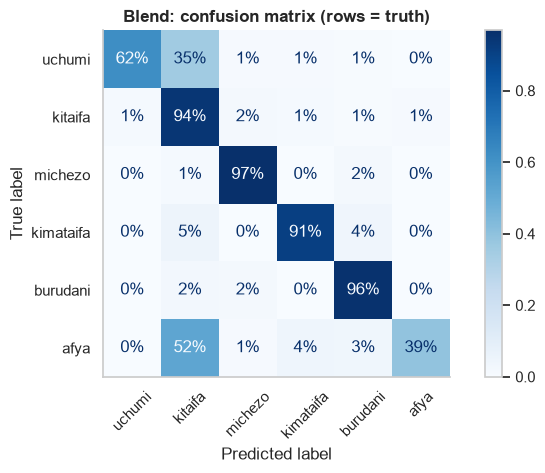

In [15]:
best_valid_pred = p_blend.argmax(1)
print(classification_report(valid["label"], best_valid_pred, target_names=[f"{l} ({LABELS_EN[l]})" for l in LABELS], digits=3))
ConfusionMatrixDisplay.from_predictions(valid["label"].map(dict(enumerate(LABELS))), pd.Series(best_valid_pred).map(dict(enumerate(LABELS))),
                                        labels=LABELS, normalize="true", values_format=".0%", cmap="Blues", xticks_rotation=45)
plt.title("Blend: confusion matrix (rows = truth)"); plt.grid(False); plt.show()

The usual confusion: **kitaifa** (national) vs **uchumi** (economy) and **kimataifa** (international). Makes sense:
a story about Tanzania's budget is both national and economic news. Some of these "errors" are debatable labels.

### Final test ("private leaderboard") and submission
Many Zindi text challenges ask for **one probability per class**: we produce both formats.

In [16]:
p_test = (softmax(trainer.predict(test_ds).predictions, axis=1) + tfidf.predict_proba(test["text"])) / 2
test_f1 = f1_score(test["label"], p_test.argmax(1), average="macro")
print(f"🏁 Test macro-F1 of the blend: {test_f1:.3f}   accuracy: {accuracy_score(test['label'], p_test.argmax(1)):.3f}")

submission = pd.DataFrame(p_test, columns=LABELS).round(5)
submission.insert(0, "id", test.index)
make_submission(submission, "swahili_news_probabilities.csv");

🏁 Test macro-F1 of the blend: 0.823   accuracy: 0.908
📤 Submission saved: submissions/swahili_news_probabilities.csv  (7338 rows, columns=['id', 'uchumi', 'kitaifa', 'michezo', 'kimataifa', 'burudani', 'afya'])


## 🏆 Quest complete!

You compared the two eras of NLP on a real African-language challenge, and combined them.

**Key takeaways**
- Always start with a TF-IDF baseline: on topic classification it is hard to beat.
- Pre-trained transformers shine with **less data** and on **subtle** tasks (sentiment, intent), and they bring
  diversity to an ensemble.
- Sub-word tokenisation handles the rich morphology of African languages.

### 🚀 Your turn (bonus XP)
1. Train the transformer on **all** 18 876 articles, or increase `MAX_LEN` to 256. How much does it gain? How much
   longer does it take?
2. Try a bigger model, e.g. `Davlan/afro-xlmr-small` or `Davlan/afro-xlmr-base` (on a GPU).
3. Weight the blend (`0.7 * bert + 0.3 * tfidf`) and tune the weight on the validation set (not on the test!).
4. Help the transformer on rare classes: pass class weights to the loss (subclass `Trainer` and override
   `compute_loss`), or oversample *afya* and *uchumi* articles.
5. Reuse this notebook on AfriSenti (quest 01): does the transformer beat TF-IDF on sentiment?

In [17]:
checkpoint("swahili_news/complete", xp=130)
badge("Habari Hunter", "📰")
progress()

✅ Checkpoint · swahili_news/complete (+130 XP)
   ██████████████████░░░░░░ 250/300 XP
╔══════════════════════════════════╗
║ 📰  BADGE UNLOCKED: Habari Hunter ║
╚══════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 3
Badges: 📰 Habari Hunter
